# Walkthrough: from outputs to the paper's tables and figures

This notebook **reads the outputs already produced by the scripts in `src/`** and shows, step by step, where each table
and figure of the paper comes from. It does not train or assign anything, so it runs in seconds.

Run order of the scripts (see README):

```
00 official workspace ─┐
01 retraining ─────────┼─► 02 reproduction + assumption checks ─► Tables 2, 3, 5, 6, 8
05 retraining at other λ ┤   07 λ comparison                   ─► Table 7, Fig. 5
                        │   08 same exact LP for both methods  ─► Table 4, Fig. 3
                        │   09 CP-SAT optimality               ─► 27/125 below the LP optimum
                        │   11 re-run vs shipped results       ─► Table 4 (authors' column), Sect. 5.1
                        └─► figures/                           ─► Fig. 1–5, key_numbers.json
```

**Where the outputs are:** the repository contains no results. The notebook reads `<L2D_ROOT>/outputs`, i.e. the
workspace the scripts wrote to. Either set the environment variable `L2D_ROOT` before starting Jupyter, or write the
workspace folder in the first code cell below.

In [1]:
import os, sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

# Workspace used by the scripts (the folder that contains outputs/). Leave None to use the L2D_ROOT environment variable.
WORKSPACE = None            # e.g. r'C:/path/to/workspace'
if WORKSPACE: os.environ['L2D_ROOT'] = WORKSPACE

sys.path.insert(0, str(Path.cwd().parent))
import config
O = config.OUTPUTS
if not (config.LAMBDA_OUT / 'solver_confound_summary_retrain.csv').exists():
    raise FileNotFoundError('No finished outputs under ' + str(O) + '. Run the scripts in src/ first (README, Run order), '
                            'or set WORKSPACE above / L2D_ROOT to the folder that holds outputs/.')
pd.set_option('display.width', 160)
print('outputs found')

outputs found


## 1. Reproduction (Table 2, Fig. 2)
`02_assumption_checks.py author|retrain` → `tables/T1_reproduction_vs_paper.csv`. The released result files match the
published Table 7; the retrained models fall within the published 95% CIs in 20 of 25 cells.

In [2]:
t1 = pd.read_csv(O / 'tables/T1_reproduction_vs_paper.csv'); t1

,team,method,paper,rerun_author_artifacts,independent_retrain,retrain_rel_diff_%,retrain_within_paper_CI
0,team_1,Full_Rej,213.5,213.5,213.5,0.0,True
1,team_1,Only_Classifier,204.0,204.0,204.0,0.0,True
2,team_1,Random,169.6,169.6,169.6,0.0,True
3,team_1,OvA,151.7,151.7,143.9,-5.1,False
4,team_1,DeCCaF,138.1,138.1,136.1,-1.5,True
5,team_2,Full_Rej,213.5,213.5,213.5,0.0,True
6,team_2,Only_Classifier,204.0,204.0,204.0,0.0,True
7,team_2,Random,157.8,157.8,157.8,-0.0,True
8,team_2,OvA,142.0,142.0,145.3,2.3,False
9,team_2,DeCCaF,145.3,145.3,133.6,-8.0,False


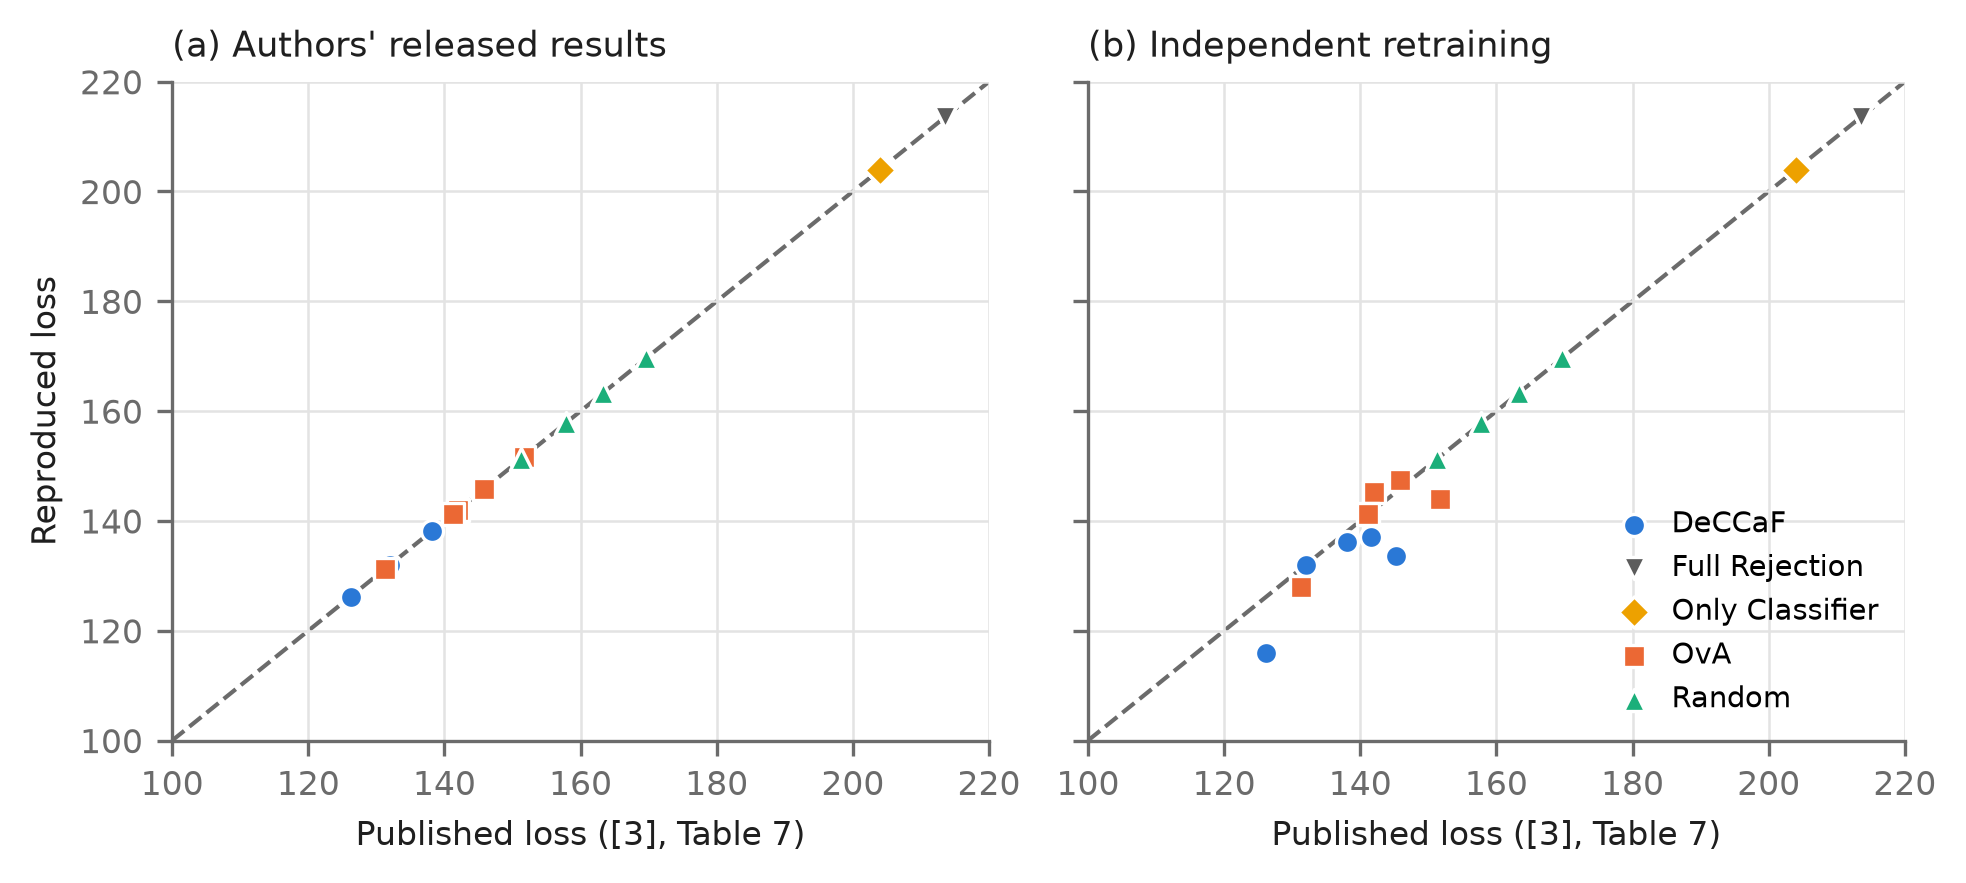

In [3]:
display(Image(filename=str(config.FIG_DIR / 'F1_reproduction_scatter.png'), width=650))

## 2. Paired comparison of the retrained models (Table 3)
Run-level paired differences over the 125 evaluation runs.

In [4]:
pd.read_csv(O / 'tables/T2_paired_statistics.csv')

,A,B,n_pairs,mean_diff,ci_low,ci_high,share_A_better,wilcoxon_p_env
0,DeCCaF,OvA,125,-10.2171,-14.6066,-5.5229,0.912,0.0
1,DeCCaF,Random,125,-30.0536,-36.3831,-23.7590,1.000,0.0
2,OvA,Random,125,-19.8364,-24.3889,-15.0584,1.000,0.0
3,DeCCaF,Only_Classifier,125,-73.0998,-84.2622,-62.1261,1.000,0.0
4,OvA,Only_Classifier,125,-62.8827,-74.7427,-51.2700,1.000,0.0


## 3. Prediction vs assignment (Table 4, Fig. 3)
`08_solver_confound.py` assigns OvA and DeCCaF with the same exact LP. For the authors' artefacts, the OvA greedy column
uses the greedy assignment recomputed from the released `ova.pkl` (`11_rerun_check.py`), because 20 released OvA result
files cannot be regenerated from that file.

In [5]:
s_author = pd.read_csv(config.LAMBDA_OUT / 'solver_confound_summary_author_ova_recomputed.csv', index_col=0).iloc[:, 0]
s_retrain = pd.read_csv(config.LAMBDA_OUT / 'solver_confound_summary_retrain.csv', index_col=0).iloc[:, 0]
pd.DataFrame({"authors' artefacts (OvA greedy recomputed)": s_author.values, 'retrained': s_retrain.values},
             index=['runs', 'OvA greedy', 'OvA exact LP', 'DeCCaF CP-SAT', 'DeCCaF exact LP', 'DeCCaF-OvA official',
                    'DeCCaF-OvA same LP', 'OvA assignment effect', 'share due to assignment'])

,authors' artefacts (OvA greedy recomputed),retrained
runs,125,125
OvA greedy,141.92279200000013,141.16331200000013
OvA exact LP,134.4087760000001,134.06823200000008
DeCCaF CP-SAT,136.6317840000001,130.94618400000007
DeCCaF exact LP,131.67788800000008,131.0093200000001
DeCCaF-OvA official,"-5.29 [-9.67, -1.19]","-10.22 [-15.51, -5.67]"
DeCCaF-OvA same LP,"-2.73 [-6.70, 1.11]","-3.06 [-6.91, 0.65]"
OvA assignment effect,"-7.51 [-11.09, -3.99]","-7.10 [-10.34, -3.95]"
share due to assignment,48.4%,70.1%


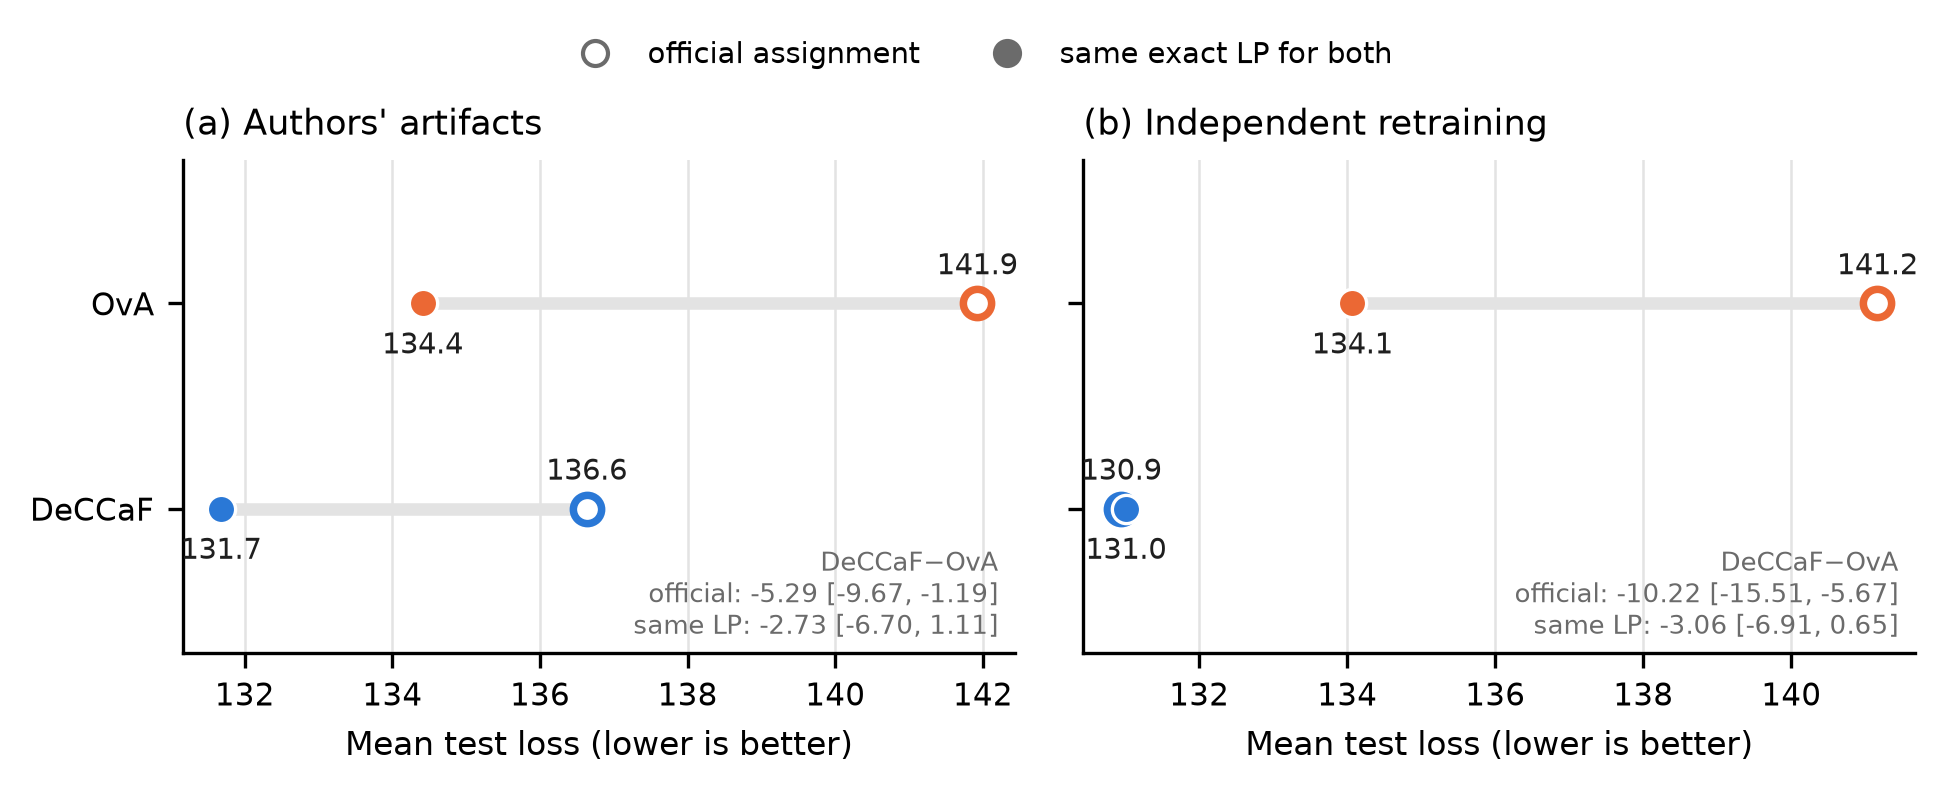

In [6]:
display(Image(filename=str(config.FIG_DIR / 'F5_assignment_confound_ova_recomputed.png'), width=650))

## 4. Released results vs a re-run of the authors' deferral script (Sect. 5.1)
`11_rerun_check.py`: file-by-file comparison and agreement of the recomputed OvA greedy assignment.

In [7]:
cmp = pd.read_csv(config.LAMBDA_OUT / 'rerun_vs_shipped_files.csv')
print(cmp.groupby('method')['identical'].agg(files='size', identical='sum').to_string())
agr = pd.read_csv(config.LAMBDA_OUT / 'ova_greedy_recomputed_agreement.csv')
print('\nOvA greedy recomputed from ova.pkl, runs identical to the re-run:', int((agr.agree_rerun == 1).sum()), '/', len(agr))
print('runs identical to the shipped files:', int((agr.agree_shipped == 1).sum()), '/', len(agr))

                 files  identical
method                           
DeCCaF             250        151
Full_Rej            50         50
Only_Classifier     50         50
OvA                250        210
Random             250        250

OvA greedy recomputed from ova.pkl, runs identical to the re-run: 125 / 125
runs identical to the shipped files: 105 / 125


## 5. Is the CP-SAT assignment optimal? (Sect. 5.3)
`09_cpsat_optimality.py` compares the stored CP-SAT objective with the LP optimum for the same scores.

In [8]:
cp = pd.read_csv(config.LAMBDA_OUT / 'cpsat_optimality_check.csv'); cp.head()

,src,seed,env,obj_cpsat,obj_lp,rel_gap,cap_match
0,author,shuffle_1#team_1,testsize#team_1-hom,3599.308725,3599.308725,0.0,True
1,author,shuffle_1#team_1,testsize#team_1-var_1,3599.179930,3599.179930,0.0,True
2,author,shuffle_1#team_1,testsize#team_1-var_2,3600.192467,3600.192467,0.0,True
3,author,shuffle_1#team_1,testsize#team_1-var_3,3599.434458,3599.434458,0.0,True
4,author,shuffle_1#team_1,testsize#team_1-var_4,3599.833647,3599.833647,0.0,True


## 6. Cost ratio λ (Table 7, Fig. 5)
`05_lambda_retrain.py` (per λ) and `07_lambda_eval.py`: re-evaluating fixed models vs retraining at each λ.

In [9]:
lam = pd.read_csv(config.LAMBDA_OUT / 'lambda_retrain_results.csv')
lam[['design', 'eval_lambda', 'setting', 'OvA', 'DeCCaF', 'DeCCaF_minus_OvA', 'ci_low', 'ci_high', 'winner']]

,design,eval_lambda,setting,OvA,DeCCaF,DeCCaF_minus_OvA,ci_low,ci_high,winner
0,"A: λ grid, 1 testbed/team",0.020,evaluation only (models trained at 0.057),81.0264,67.4168,-13.6096,-20.4089,-7.4613,DeCCaF
1,"A: λ grid, 1 testbed/team",0.020,retrained at this λ,72.2552,56.3424,-15.9128,-21.8874,-9.5542,DeCCaF
2,"A: λ grid, 1 testbed/team",0.057,evaluation only (models trained at 0.057),140.0532,132.8639,-7.1894,-14.1344,-0.7342,DeCCaF
3,"A: λ grid, 1 testbed/team",0.100,evaluation only (models trained at 0.057),208.6520,208.9240,0.2720,-7.0040,7.3921,no significant difference
4,"A: λ grid, 1 testbed/team",0.100,retrained at this λ,198.2280,206.5320,8.3040,2.7478,14.1288,OvA
5,"A: λ grid, 1 testbed/team",0.200,evaluation only (models trained at 0.057),368.1840,385.8080,17.6240,9.0070,26.2162,OvA
6,"A: λ grid, 1 testbed/team",0.200,retrained at this λ,315.5760,320.3520,4.7760,-3.3852,12.7616,no significant difference
7,"A: λ grid, 1 testbed/team",0.500,evaluation only (models trained at 0.057),846.7800,916.4600,69.6800,54.6385,86.3405,OvA
8,"A: λ grid, 1 testbed/team",0.500,retrained at this λ,647.3800,600.4600,-46.9200,-62.8020,-32.2950,DeCCaF
9,B: 5 testbeds/team,0.100,evaluation only (models trained at 0.057),202.2136,206.2920,4.0784,-0.0859,8.1302,no significant difference


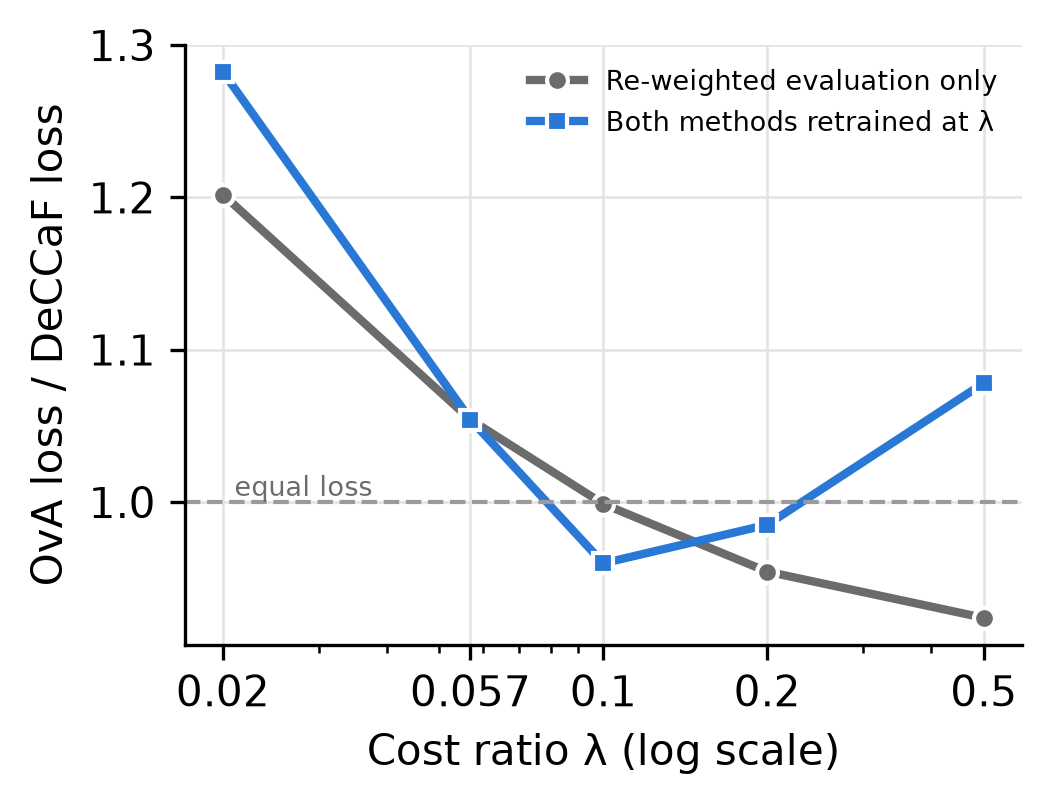

In [10]:
display(Image(filename=str(config.FIG_DIR / 'F3b_lambda_retrained.png'), width=650))

## 7. Temporal drift (Fig. 4) and oracle headroom (Table 8)

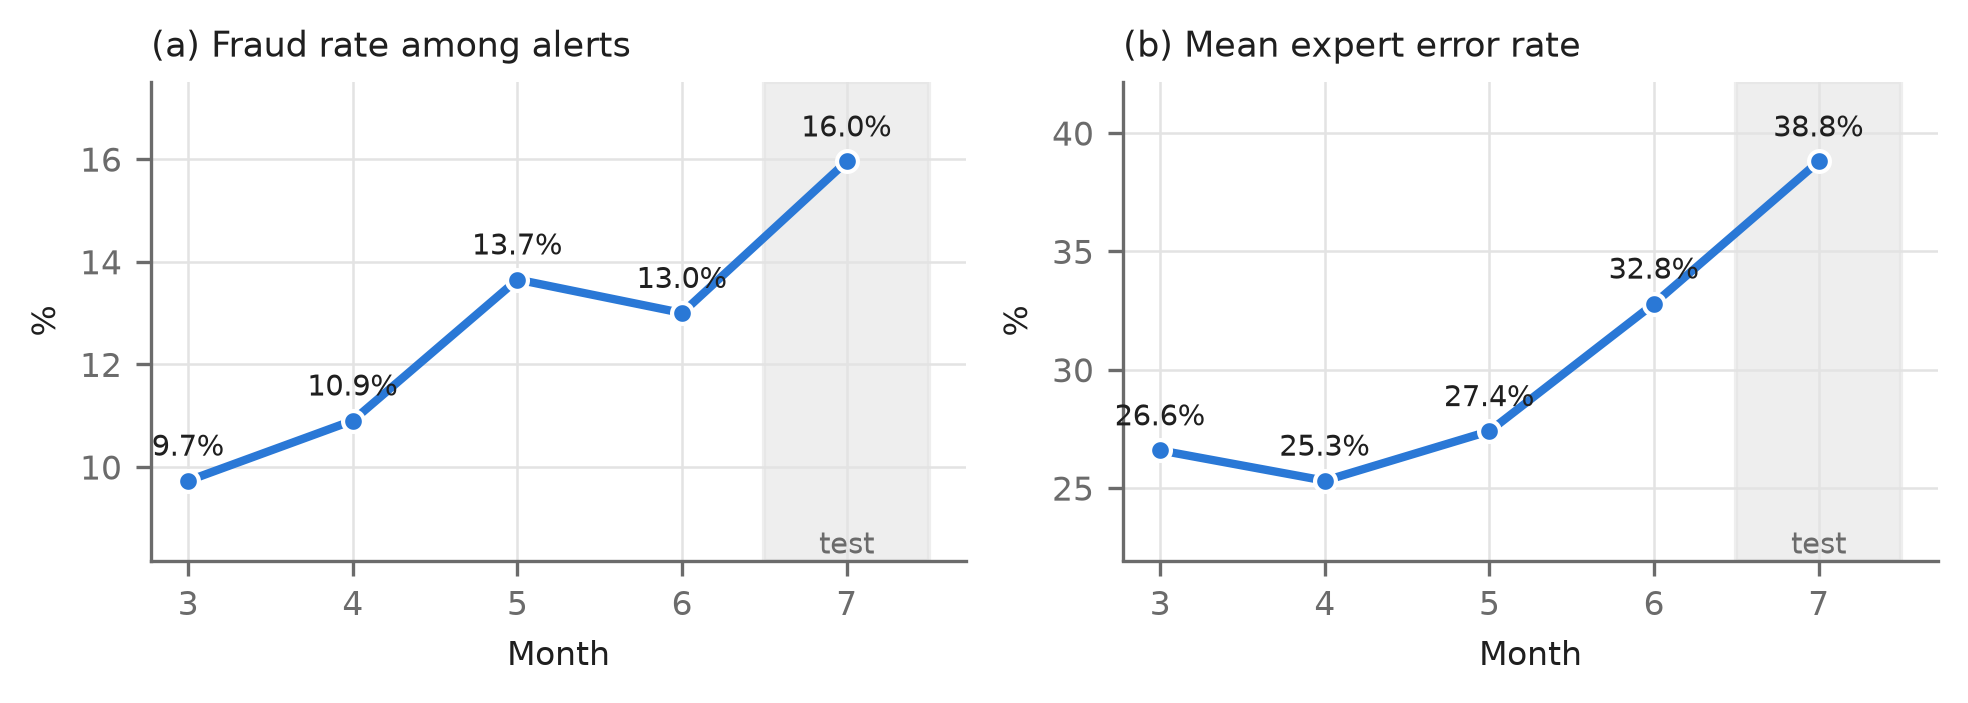

,team,Random,OvA,DeCCaF,LabelOracle
0,team_1,169.63,143.93,136.08,106.15
1,team_2,157.78,145.29,133.63,122.55
2,team_3,151.23,127.92,116.03,99.34
3,team_4,163.05,147.49,136.98,104.21
4,team_5,163.30,141.18,132.01,113.08


In [11]:
display(Image(filename=str(config.FIG_DIR / 'F2_monthly_drift.png'), width=650))
pd.read_csv(O / 'tables/T4_headroom_by_team.csv')

## 8. Numbers quoted in the text
`figures/fig_tables_main.py` writes `key_numbers.json`.

In [12]:
json.loads((O / 'key_numbers.json').read_text())

{'retrain_within_paper_CI': '20/25',
 'author_artifacts_within_paper_CI': '25/25',
 'mean_loss_retrain': {'Full_Rej': 213.5,
  'Only_Classifier': 204.0,
  'Random': 161.0,
  'OvA': 141.2,
  'DeCCaF': 130.9},
 'mean_loss_paper': {'Full_Rej': 213.5,
  'Only_Classifier': 204.0,
  'Random': 161.0,
  'OvA': 142.4,
  'DeCCaF': 136.6},
 'gap_to_label_oracle_rel': {'retrain': 0.1658, 'author': 0.2002},
 'auc_ece_experts': {'DeCCaF': {'auc': 0.616, 'ece': 0.048},
  'OvA': {'auc': 0.591, 'ece': 0.057}},
 'rescuable_share_range': [0.842, 0.942],
 'features_ks_ge_0.1': 8,
 'top_ks': [{'feature': 'velocity_4w', 'ks': 0.848},
  {'feature': 'velocity_24h', 'ks': 0.491},
  {'feature': 'zip_count_4w', 'ks': 0.311}],
 'lambda_0.5': {'DeCCaF': 906.0, 'OvA': 892.1},
 'solver_check': {'official_cp_sat': 130.9, 'exact_lp': 131.0}}